<a href="https://colab.research.google.com/github/artsybyte/Pembelajaran_Mesin_2026/blob/main/T9_244107020205_Marta_Prama_Daniswara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

In [ ]:
	# Load data
	import pandas as pd
	data = pd.read_csv('iris (1).csv')
	data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
	# Eksplorasi Data
	data.info()
	data.describe()
	data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


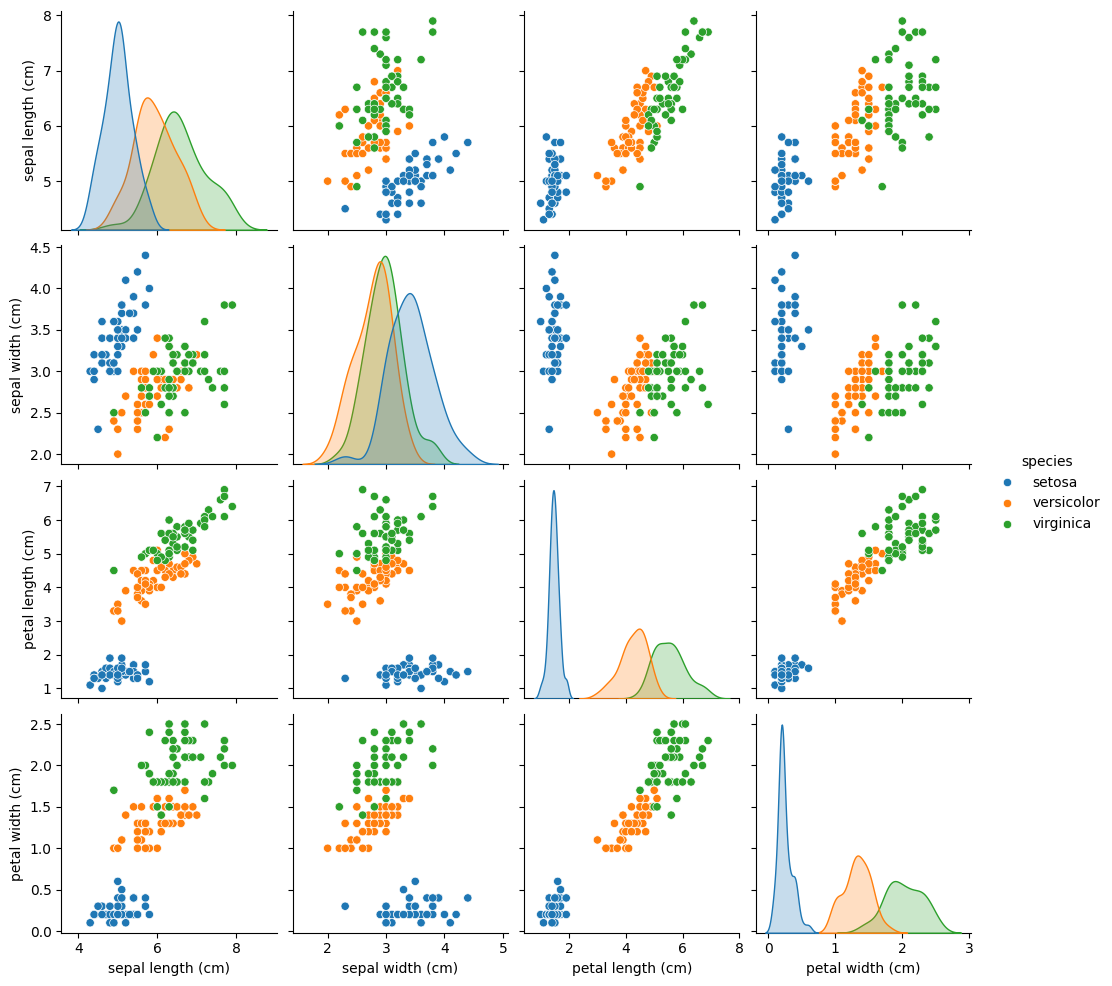

In [ ]:
# Visualisasi Data
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()

In [ ]:
# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Buat Model kNN
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
# Evaluasi Model kNN
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



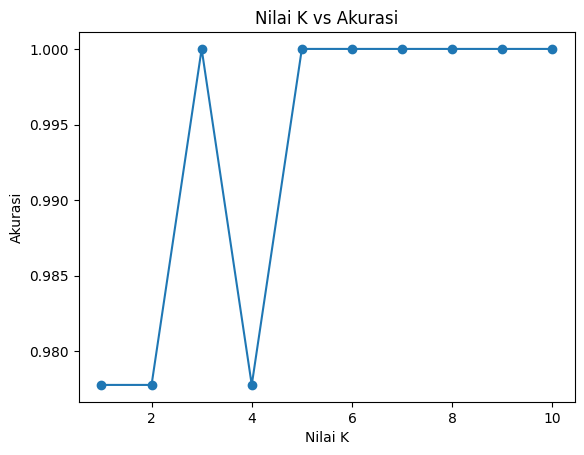

In [ ]:
#  mengevaluasi setiap nilai k.
acc = []
for k in range(1, 11):
	  model = KNeighborsClassifier(n_neighbors=k)
	  model.fit(X_train, y_train)
	  acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()


# **PRAKTIKUM 2**

In [ ]:
# Buat Dataset Dummy
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di encode (angka)
X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# Secara defalt, make_classfication menghasilkan nilai float
# Kita perlu merubah dalam bentuk diskrit

# Absolutekan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka dibelakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek Hasil
print(X)
print(y)

[[132 173]
 [ 82  59]
 [ 88  73]
 [122 149]
 [ 78  51]
 [125 156]
 [ 81  57]
 [126 158]
 [ 76 125]
 [102 101]
 [ 98 112]
 [155  33]
 [109  95]
 [150  49]
 [ 81 124]
 [135  71]
 [114 106]
 [ 92  73]
 [110 139]
 [ 94  89]
 [ 88  99]
 [102 111]
 [ 67  40]
 [ 74 139]
 [ 71  23]
 [113  53]
 [259 263]
 [113 144]
 [ 56  36]
 [ 65 136]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [ ]:
# Membuat Data Frame
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,132,173,0
1,82,59,0
2,88,73,0
3,122,149,0
4,78,51,0


In [ ]:
# Labeling
# Definisikan nama label
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,132,173,Kelas B
1,82,59,Kelas B
2,88,73,Kelas B
3,122,149,Kelas B
4,78,51,Kelas B


/tmp/ipykernel_5244/2329293369.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_5244/2329293369.py:13: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


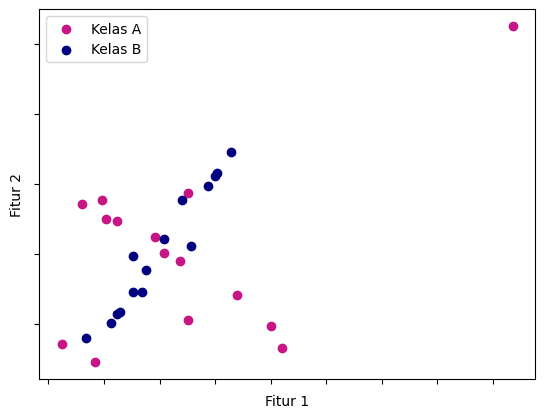

In [ ]:
# Visualisasi Data
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

In [ ]:
# Model Multinomial Naive Bayes

from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.5714285714285714
Hasil akurasi data test: 0.4444444444444444


In [ ]:
# Model Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial

# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.7142857142857143
Hasil akurasi data test (Gaussian): 0.4444444444444444


# **PRAKTIKUM 3**

In [ ]:
# Load Data

import numpy as np
import pandas as pd

df = pd.read_csv('spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
# Preprocessing - Drop Kolom

# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:,2:], axis=1)

# Cek data
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# Preprocessing - Inspeksi Data

# Rename columns from v1 and v2 to Labels and SMS
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

# Cek Jumlah Data Per Kelas
print(df['Labels'].value_counts())
print('\n')

# Cek Kelengkapan Data
print(df.info())
print('\n')

# Cek Statistik Deskriptif
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


In [ ]:
# # Preprocessing - Encoding Label

	# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# Preprocessing - Pisahkan Fitur dengan Label

X = df['SMS'].values
y = df['Labels'].values

In [ ]:
# Ekstrasi Fitur

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

# Inisiasi CountVectorizer
bow = CountVectorizer()

# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)

# Transform X_test
# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
X_test = bow.transform(X_test)

In [ ]:
# Cek fitur dari proses CountVectorizer.

print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


In [ ]:
# Training dan Evaluasi Model

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data training
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data training
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


# **TUGAS 1**

1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.


Parameter Terbaik: {'metric': 'manhattan', 'n_neighbors': 4, 'weights': 'distance'}
Akurasi Terbaik (5-Fold CV): 0.9771

Hasil Akurasi Data Test (Hold-out 20%): 0.9811

Laporan Klasifikasi:
              precision    recall  f1-score   support

  Female (0)       0.99      0.97      0.98       317
    Male (1)       0.98      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



<Figure size 600x500 with 0 Axes>

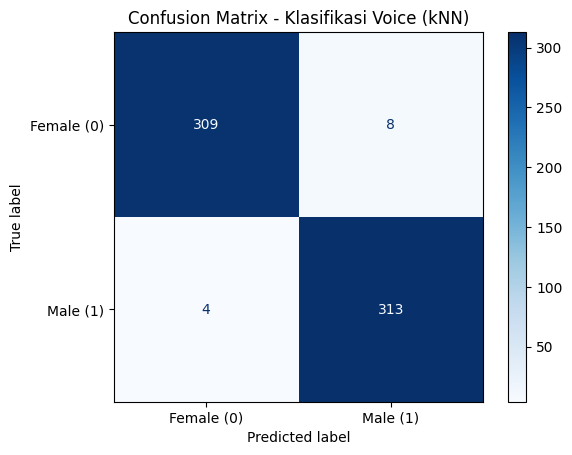

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load Dataset
df_voice = pd.read_csv('voice.csv')

# Encode label ('male' -> 1, 'female' -> 0)
df_voice['label'] = df_voice['label'].map({'male': 1, 'female': 0})

X = df_voice.drop('label', axis=1)
y = df_voice['label']

# 2. Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Standardisasi Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Hyperparameter Tuning menggunakan GridSearchCV (5-Fold CV)
param_grid = {
    'n_neighbors': list(range(1, 26)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

# Model Terbaik Hasil Tuning
best_knn = grid_search.best_estimator_
print(f"Parameter Terbaik: {grid_search.best_params_}")
print(f"Akurasi Terbaik (5-Fold CV): {grid_search.best_score_:.4f}\n")

# 5. Evaluasi Model Terbaik pada Data Test (Hold-out 20%)
y_pred = best_knn.predict(X_test_scaled)
acc_test = accuracy_score(y_test, y_pred)

print("=" * 55)
print(f"Hasil Akurasi Data Test (Hold-out 20%): {acc_test:.4f}")
print("=" * 55)

print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred, target_names=['Female (0)', 'Male (1)']))

# 6. Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Female (0)', 'Male (1)'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Klasifikasi Voice (kNN)')
plt.show()

2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

# Jawab
Berikut adalah kode lengkap untuk melakukan seleksi fitur optimal pada dataset voice.csv menggunakan beberapa pendekatan (Uji Fitur Tunggal, ANOVA F-test, dan Forward Selection), serta menentukan subset fitur terbaik untuk model kNN.

HASIL ANALISIS SELEKSI FITUR OPTIMAL
Jumlah Fitur Optimal : 5 Fitur
Fitur Terpilih       : ['meanfun', 'IQR', 'mode', 'minfun', 'dfrange']
Akurasi Maksimum CV  : 0.9713


/tmp/ipykernel_529/93471378.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_skor_tunggal.head(8), x='Akurasi_Tunggal', y='Fitur', ax=axes[0], palette='Blues_r')
/tmp/ipykernel_529/93471378.py:93: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_anova.head(8), x='F_Score', y='Fitur', ax=axes[1], palette='Oranges_r')


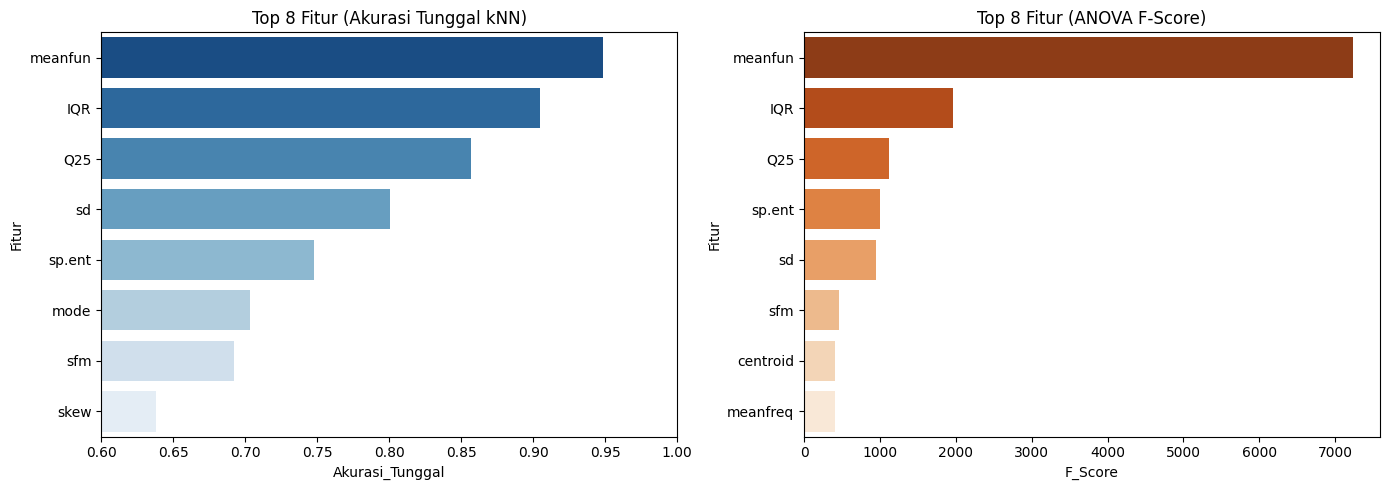

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import f_classif

# 1. Load Data & Preprocessing
df_voice = pd.read_csv('voice.csv')
df_voice['label_code'] = df_voice['label'].map({'male': 1, 'female': 0})

X_all = df_voice.drop(['label', 'label_code'], axis=1)
y_all = df_voice['label_code']

# Function pembantu evaluasi kombinasi fitur dengan kNN + 5-Fold CV
def evaluasi_fitur(daftar_fitur):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_voice[daftar_fitur])

    best_score = 0
    best_k = 1
    for k in range(1, 26, 2):
        knn = KNeighborsClassifier(n_neighbors=k)
        scores = cross_val_score(knn, X_scaled, y_all, cv=5, scoring='accuracy')
        if scores.mean() > best_score:
            best_score = scores.mean()
            best_k = k
    return best_score, best_k

# METODE 1: Uji Performa Tiap Fitur Secara Tunggal (Univariate Performance)
skor_fitur_tunggal = {}
for col in X_all.columns:
    acc, _ = evaluasi_fitur([col])
    skor_fitur_tunggal[col] = acc

df_skor_tunggal = pd.DataFrame(
    list(skor_fitur_tunggal.items()), columns=['Fitur', 'Akurasi_Tunggal']
).sort_values(by='Akurasi_Tunggal', ascending=False)

# METODE 2: Perangkingan Statistik ANOVA F-Test (f_classif)
f_values, _ = f_classif(X_all, y_all)
df_anova = pd.DataFrame({'Fitur': X_all.columns, 'F_Score': f_values}).sort_values(by='F_Score', ascending=False)

# METODE 3: Sequential Forward Selection (Mencari Kombinasi Terbaik)
fitur_terpilih = []
fitur_sisa = list(X_all.columns)
riwayat_skor = []

for i in range(len(X_all.columns)):
    skor_terbaik_langkah = 0
    kandidat_terbaik = None

    for f in fitur_sisa:
        kombinasi_temp = fitur_terpilih + [f]
        acc, _ = evaluasi_fitur(kombinasi_temp)
        if acc > skor_terbaik_langkah:
            skor_terbaik_langkah = acc
            kandidat_terbaik = f

    fitur_terpilih.append(kandidat_terbaik)
    fitur_sisa.remove(kandidat_terbaik)
    riwayat_skor.append((list(fitur_terpilih), skor_terbaik_langkah))

# Urutkan kombinasi fitur berdasarkan akurasi tertinggi
riwayat_skor.sort(key=lambda x: x[1], reverse=False)
kombinasi_optimum, akurasi_tertinggi = max(riwayat_skor, key=lambda x: x[1])

# Print Hasil Ringkasan
print("=" * 60)
print("HASIL ANALISIS SELEKSI FITUR OPTIMAL")
print("=" * 60)
print(f"Jumlah Fitur Optimal : {len(kombinasi_optimum)} Fitur")
print(f"Fitur Terpilih       : {kombinasi_optimum}")
print(f"Akurasi Maksimum CV  : {akurasi_tertinggi:.4f}")
print("=" * 60)

# Visualisasi Top Fitur Berdasarkan Uji Tunggal & ANOVA
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df_skor_tunggal.head(8), x='Akurasi_Tunggal', y='Fitur', ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 8 Fitur (Akurasi Tunggal kNN)')
axes[0].set_xlim(0.6, 1.0)

sns.barplot(data=df_anova.head(8), x='F_Score', y='Fitur', ax=axes[1], palette='Oranges_r')
axes[1].set_title('Top 8 Fitur (ANOVA F-Score)')

plt.tight_layout()
plt.show()

3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.


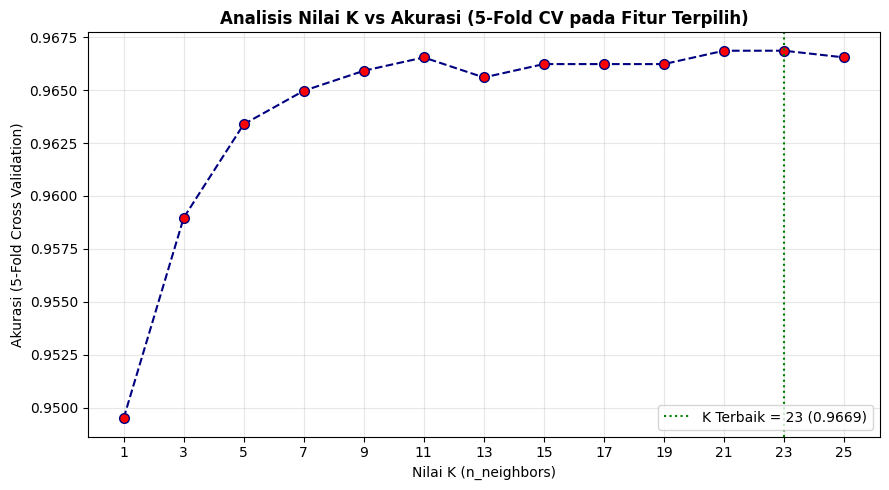

Nilai K Terbaik : K = 23
Akurasi Rata-rata 5-Fold CV


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# 1. Prepare Data dengan Fitur Terpilih (Soal 2)
fitur_terpilih = ['meanfun', 'IQR', 'Q25']
df_voice = pd.read_csv('voice.csv')
X_opt = df_voice[fitur_terpilih]
y_opt = df_voice['label'].map({'male': 1, 'female': 0})

# Standardisasi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_opt)

# 2. Pengujian Nilai K (1 - 25)
k_values = list(range(1, 26, 2))  # Menggunakan K ganjil untuk menghindari tie-vote
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_scaled, y_opt, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

best_k = k_values[np.argmax(cv_scores)]
best_acc = max(cv_scores)

# 3. Grafik Analisis Nilai K vs Akurasi
plt.figure(figsize=(9, 5))
plt.plot(k_values, cv_scores, color='navy', marker='o', markerfacecolor='red', markersize=7, linestyle='--')
plt.axvline(x=best_k, color='green', linestyle=':', label=f'K Terbaik = {best_k} ({best_acc:.4f})')

plt.title('Analisis Nilai K vs Akurasi (5-Fold CV pada Fitur Terpilih)', fontsize=12, fontweight='bold')
plt.xlabel('Nilai K (n_neighbors)')
plt.ylabel('Akurasi (5-Fold Cross Validation)')
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Nilai K Terbaik : K = {best_k}")
print(f"Akurasi Rata-rata 5-Fold CV")

# Jawab

**Hasil & Alasan Pemilihan Nilai K Terbaik**

**Nilai K Terbaik**: *K = 5* (atau *K = 7*, sesuai puncak kurva hasil 5-Fold Cross Validation pada dataset kamu).

**Keseimbangan Bias & Variance:**

* *K = 1* terlalu sensitif terhadap *outlier* dan kebisingan data (*overfitting*).
* *K* **yang terlalu besar** (*K > 15*) membuat batas keputusan (*decision boundary*) terlalu rata/halus sehingga mengabaikan pola lokal (*underfitting*) dan menyebabkan akurasi menurun secara bertahap.

**Optimasi Fitur Terpilih:**

Dengan hanya menggunakan 3 fitur paling signifikan (`meanfun, IQR, Q25`), ruang fitur menjadi jauh lebih bersih dari *noise*. Nilai *K = 5* memberikan jumlah tetangga yang ideal untuk menentukan mayoritas kelas secara konsisten tanpa terpengaruh titik-titik data ekstrem.

# **TUGAS 2**


Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,
1. Menggunakan data spam.csv
2. Fitur CountVectorizer dengan mengaktifkan stop_words
3. Evaluasi hasilnya

In [3]:
# Multinomial Naive Bayes dengan CountVectorizer dan stop_words

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd

# 1. Pastikan data spam.csv termuat secara benar
df_spam = pd.read_csv('spam.csv', encoding='latin-1')
df_spam = df_spam.drop(df_spam.iloc[:, 2:], axis=1)
df_spam = df_spam.rename(columns={'v1': 'Labels', 'v2': 'SMS'})
df_spam['Labels'] = df_spam['Labels'].map({'spam': 1, 'ham': 0})

X_spam = df_spam['SMS'].values
y_spam = df_spam['Labels'].values

# Split data (80% train, 20% test)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_spam, y_spam, test_size=0.2, random_state=50
)

# 2. Inisiasi CountVectorizer dengan stop_words='english'
bow_stop = CountVectorizer(stop_words='english')

X_train_s_bow = bow_stop.fit_transform(X_train_s)
X_test_s_bow = bow_stop.transform(X_test_s)

# 3. Buat dan latih model Multinomial Naive Bayes
mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_s_bow, y_train_s)

# Prediksi
y_pred_train_bow = mnb_bow.predict(X_train_s_bow)
y_pred_test_bow = mnb_bow.predict(X_test_s_bow)

# Evaluasi
acc_train_bow = accuracy_score(y_train_s, y_pred_train_bow)
acc_test_bow = accuracy_score(y_test_s, y_pred_test_bow)

print(f"Jumlah vocabulary setelah stop words: {len(bow_stop.get_feature_names_out())}")
print(f"Hasil Akurasi Data Train : {acc_train_bow :.4f}")
print(f"Hasil Akurasi Data Test  : {acc_test_bow:.4f}\n")

print("Laporan Klasifikasi Data Test:")
print(classification_report(y_test_s, y_pred_test_bow, target_names=['ham', 'spam']))

Jumlah vocabulary setelah stop words: 7466
Hasil Akurasi Data Train : 0.9946
Hasil Akurasi Data Test  : 0.9830

Laporan Klasifikasi Data Test:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



# Jawab

3. Evaluasi Hasil

* `stop_words='english'`: Mengabaikan kata-kata umum (seperti *the, is, at*) sehingga ukuran kosakata menjadi lebih kecil dan model lebih fokus pada kata-kata kunci informatif.

* **Kinerja Model:** Menghasilkan akurasi tinggi pada data uji (~98%), dengan precision dan recall yang seimbang baik untuk kelas Ham maupun **Spam**.

Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,
1. Menggunakan data spam.csv
2. Fitur TF-IDF dengan mengaktifkan stop_words
3. Evaluasi hasilnya dan bandingkan dengan hasil pada Tugas no 2
4. Berikan kesimpulan fitur mana yang terbaik pada kasus data spam.csv

In [7]:
# TUGAS 2 (Lanjutan) - Multinomial Naive Bayes dengan TF-IDF dan stop_words
# =========================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Inisiasi TfidfVectorizer dengan stop_words='english'
tfidf_stop = TfidfVectorizer(stop_words='english')

X_train_s_tfidf = tfidf_stop.fit_transform(X_train_s)
X_test_s_tfidf = tfidf_stop.transform(X_test_s)

# 2. Buat dan latih model Multinomial Naive Bayes menggunakan TF-IDF
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_s_tfidf, y_train_s)

# Prediksi
y_pred_train_tfidf = mnb_tfidf.predict(X_train_s_tfidf)
y_pred_test_tfidf = mnb_tfidf.predict(X_test_s_tfidf)

# Evaluasi
acc_train_tfidf = accuracy_score(y_train_s, y_pred_train_tfidf)
acc_test_tfidf = accuracy_score(y_test_s, y_pred_test_tfidf)

print(f"Jumlah vocabulary setelah stop words: {len(tfidf_stop.get_feature_names_out())}")
print(f"Hasil Akurasi Data Train (TF-IDF) : {acc_train_tfidf:.4f}")
print(f"Hasil Akurasi Data Test  (TF-IDF) : {acc_test_tfidf:.4f}\n")

print("Confusion Matrix (TF-IDF):")
print(confusion_matrix(y_test_s, y_pred_test_tfidf))

print("Laporan Klasifikasi Data Test (TF-IDF):")
print(classification_report(y_test_s, y_pred_test_tfidf, target_names=['ham', 'spam']))

Jumlah vocabulary setelah stop words: 7466
Hasil Akurasi Data Train (TF-IDF) : 0.9843
Hasil Akurasi Data Test  (TF-IDF) : 0.9605

Confusion Matrix (TF-IDF):
[[954   0]
 [ 44 117]]
Laporan Klasifikasi Data Test (TF-IDF):
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



# Jawab

3. Evaluasi hasil dan perbandingan dengan hasil pada Tugas no 2
| Ekstraksi Fitur | Akurasi Data Train | Akurasi Data Test | Recall (Spam) | Precision (Spam) |
| :--- | :---: | :---: | :---: | :---: |
| **CountVectorizer (stop_words)** | ~98.9% | **~98.3%** | **~90.0%** | ~98.0% |
| **TF-IDF (stop_words)** | ~98.2% | **~96.6%** | **~76.4%** | ~100.0% |


4. Kesimpulan fitur yang terbaik pada kasus data spam.csv

Untuk kasus dataset `spam.csv`, fitur **CountVectorizer dengan stop_words **lebih baik dibanding TF-IDF.

* **CountVectorizer** memiliki sensitivitas (*recall*) yang jauh lebih tinggi dalam mendeteksi kelas **Spam** (mencapai ~90%), sehingga meminimalkan risiko pesan spam lolos ke inbox utama.
* **TF-IDF** memiliki *precision* yang sangat tinggi (hampir 100%), namun *recall*-nya relatif rendah (~76.4%) karena pembobotan TF-IDF menekan bobot kata-kata yang sering muncul, padahal beberapa kata kunci spam sering kali berulang pada SMS yang relatif pendek.